In [ ]:
# Importación de librerias a utilizar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import requests
from io import BytesIO

In [ ]:
# Carga de la base de datos. Se conecta al archivo en google drive sin necesidad de descargarla manualmente
file_id = "1ST0AAdSvuajzXIoJ6gd2VhpSm5a-I1kn"
dwn_url = f"https://drive.google.com/uc?export=download&id={file_id}"

response = requests.get(dwn_url)
response.raise_for_status()

df = pd.read_excel(BytesIO(response.content))

In [ ]:
# Se verifica que se haya cargado correctamente
df.head()

,Identificador,Fec. Operación,Rango de precio,Nivel de Mantenimiento,N. Puertas,N. Personas,Tamaño maletero,Seguridad,Estado del Vehiculo,Precio de venta (USD),Costo(USD),Canal de venta,Segmento
0,1,25/01/2021,vhigh,vhigh,2,2,small,low,unacc,36822.0,31298.7,Showroom,Premium
1,2,18/01/2021,vhigh,vhigh,2,2,small,med,unacc,37696.0,32041.6,Showroom,Premium
2,3,20/01/2023,vhigh,vhigh,2,2,small,high,unacc,39634.0,33688.9,Showroom,Premium
3,4,17/01/2023,vhigh,vhigh,2,2,med,low,unacc,36290.0,30846.5,Showroom,Premium
4,5,04/01/2021,vhigh,vhigh,4,more,med,med,unacc,36404.0,30943.4,Showroom,Premium


In [ ]:
df.sample(5)

,Identificador,Fec. Operación,Rango de precio,Nivel de Mantenimiento,N. Puertas,N. Personas,Tamaño maletero,Seguridad,Estado del Vehiculo,Precio de venta (USD),Costo(USD),Canal de venta,Segmento
348,349,12/01/2020,vhigh,low,3,more,big,med,unacc,38532.0,32752.20,Online,Premium
803,804,03/01/2021,high,low,3,more,small,high,acc,24525.0,20110.50,Showroom,Ejecutivo
609,610,10/01/2022,high,high,4,4,big,low,unacc,24625.0,20192.50,Corporativo,Ejecutivo
1039,1040,20/01/2023,med,high,4,4,med,med,acc,17424.0,13590.72,Online,Familiar
22,23,29/01/2021,vhigh,vhigh,2,4,med,med,unacc,38798.0,32978.30,Corporativo,Premium


# Análisis Exploratorio y Transformación de Datos

In [ ]:
# Dimensiones del df
df.shape

(1728, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Identificador           1728 non-null   int64  
 1   Fec. Operación          1728 non-null   object 
 2   Rango de precio         1728 non-null   object 
 3   Nivel de Mantenimiento  1728 non-null   object 
 4   N. Puertas              1728 non-null   object 
 5   N. Personas             1728 non-null   object 
 6   Tamaño maletero         1728 non-null   object 
 7   Seguridad               1728 non-null   object 
 8   Estado del Vehiculo     1728 non-null   object 
 9   Precio de venta (USD)   1728 non-null   float64
 10  Costo(USD)              1728 non-null   float64
 11  Canal de venta          1728 non-null   object 
 12  Segmento                1728 non-null   object 
dtypes: float64(2), int64(1), object(10)
memory usage: 175.6+ KB


El dataframe no presenta valores nulos

In [ ]:
# Se estandariza y cambia el nombre de las columnas
df.columns = ['id', 'fecha_operacion', 'rango_precio', 'nivel_mantenimiento', 'numero_puertas', 'numero_personas',"tamaño_maletero","seguridad","estado_vehiculo","precio_venta(USD)","costo(USD)","canal_venta","segmento"]

In [ ]:
df.head(1) # Se corroboran los nombres

,id,fecha_operacion,rango_precio,nivel_mantenimiento,numero_puertas,numero_personas,tamaño_maletero,seguridad,estado_vehiculo,precio_venta(USD),costo(USD),canal_venta,segmento
0,1,25/01/2021,vhigh,vhigh,2,2,small,low,unacc,36822.0,31298.7,Showroom,Premium


#### Valores de cada columna categórica

In [ ]:
df["rango_precio"].unique()

array(['vhigh', 'med', 'low', 'high'], dtype=object)

In [ ]:
df["nivel_mantenimiento"].unique()

array(['vhigh', 'high', 'med', 'low'], dtype=object)

In [ ]:
df["numero_puertas"].unique()

array([2, 4, 3, '5more'], dtype=object)

In [ ]:
df["numero_personas"].unique()

array([2, 'more', 4], dtype=object)

In [ ]:
df["tamaño_maletero"].unique()

array(['small', 'med', 'big'], dtype=object)

In [ ]:
df["seguridad"].unique()

array(['low', 'med', 'high'], dtype=object)

In [ ]:
df["estado_vehiculo"].unique()

array(['unacc', 'acc', 'vgood', 'good'], dtype=object)

In [ ]:
df["canal_venta"].unique()

array(['Showroom', 'Online', 'Corporativo'], dtype=object)

In [ ]:
df["segmento"].unique()

array(['Premium', 'Compacto', 'Económico', 'Familiar', 'Ejecutivo'],
      dtype=object)

Todos los valores son congruentes y no hay errores en los datos

#### Transformaciones en columnas

In [ ]:
# id a tipo object
df["id"] = df["id"].astype("object")
print(df["id"].dtype)

object


In [ ]:
# fecha a tipo fecha
df['fecha_operacion'] = pd.to_datetime(df['fecha_operacion'])
print(df["fecha_operacion"].dtype)

datetime64[ns]


/tmp/ipykernel_4041/2020365983.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['fecha_operacion'] = pd.to_datetime(df['fecha_operacion'])


In [ ]:
# las variables categroicas que presentan un orden se pasan a categorical
df.rango_precio = pd.Categorical(df.rango_precio,
               categories = ['low','med','high','vhigh'],
               ordered = True)

In [ ]:
df.nivel_mantenimiento = pd.Categorical(df.nivel_mantenimiento,
               categories = ['low','med','high','vhigh'],
               ordered = True)

In [ ]:
# remplazamos en numero de puertas "5more" por "5 or more"
df['numero_puertas'] = df['numero_puertas'].replace({
    '5more': '5 or more',
})

In [ ]:
df['numero_puertas'].unique()

array([2, 4, 3, '5 or more'], dtype=object)

In [ ]:
df.numero_puertas = pd.Categorical(df.numero_puertas,
               categories = [2,3,4,'5 or more'],
               ordered = True)

In [ ]:
# remplazamos en numero de personas "more" por "5 or more"
df['numero_personas'] = df['numero_personas'].replace({
    'more': '5 or more',
})

In [ ]:
df['numero_personas'].unique()

array([2, '5 or more', 4], dtype=object)

In [ ]:
df.numero_personas = pd.Categorical(df.numero_personas,
               categories = [2,4,'5 or more'],
               ordered = True)

In [ ]:
df.tamaño_maletero = pd.Categorical(df.tamaño_maletero,
               categories = ['small', 'med', 'big'],
               ordered = True)

In [ ]:
df.estado_vehiculo = pd.Categorical(df.estado_vehiculo,
               categories = ['unacc','acc','good','vgood'],
               ordered = True)

In [ ]:
df.seguridad = pd.Categorical(df.seguridad,
               categories = ['low','med','high'],
               ordered = True)

In [ ]:
# Se pasan los valores de canal de venta y segmento a minuscula
df['canal_venta'] = df['canal_venta'].str.lower()

In [ ]:
df['canal_venta'].unique()

array(['showroom', 'online', 'corporativo'], dtype=object)

In [ ]:
df['segmento'] = df['segmento'].str.lower()

In [ ]:
df['segmento'].unique()

array(['premium', 'compacto', 'económico', 'familiar', 'ejecutivo'],
      dtype=object)

In [ ]:
# Resumen del dataframe luego de las transformaciones realizadas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   1728 non-null   object        
 1   fecha_operacion      1728 non-null   datetime64[ns]
 2   rango_precio         1728 non-null   category      
 3   nivel_mantenimiento  1728 non-null   category      
 4   numero_puertas       1728 non-null   category      
 5   numero_personas      1728 non-null   category      
 6   tamaño_maletero      1728 non-null   category      
 7   seguridad            1728 non-null   category      
 8   estado_vehiculo      1728 non-null   category      
 9   precio_venta(USD)    1728 non-null   float64       
 10  costo(USD)           1728 non-null   float64       
 11  canal_venta          1728 non-null   object        
 12  segmento             1728 non-null   object        
dtypes: category(7), datetime64[ns](1)

In [ ]:
# fecha min y max
fecha_minima = min(df.fecha_operacion)
fecha_maxima = max(df.fecha_operacion)

print(f"La fecha de inicio del registro es: {fecha_minima}")
print(f"La fecha de fin del registros es: {fecha_maxima}")

La fecha de inicio del registro es: 2020-01-01 00:00:00
La fecha de fin del registros es: 2023-01-31 00:00:00


In [ ]:
diferencia_fechas = max(df.fecha_operacion)-min(df.fecha_operacion)
print(f"La diferencia entre fechas es de: {diferencia_fechas}")

La diferencia entre fechas es de: 1126 days 00:00:00


El dataset abarca un periodo de 1126 días

In [ ]:
# Estadísticas descriptivas de las variables numéricas
df[["precio_venta(USD)","costo(USD)"]].describe().round(2)

,precio_venta(USD),costo(USD)
count,1728.00,1728.00
mean,23427.97,19114.55
std,9896.08,8911.56
min,11400.00,8550.00
25%,17167.50,13390.65
50%,18810.00,14671.80
75%,36366.00,30911.10
max,39900.00,33915.00


Se puede apreciar que el precio de venta promedio de los vehículos es de aproximadamente USD 23.428, con una mediana de USD 18.810. La diferencia entre ambos valores sugiere una distribución ligeramente sesgada hacia precios más altos, lo cual es consistente con la presencia de vehículos de gama “Premium” dentro de la oferta por parte de la concesionaria. La mediana del precio de venta supera consistentemente a la del costo, lo que indica una operación rentable en términos generales.

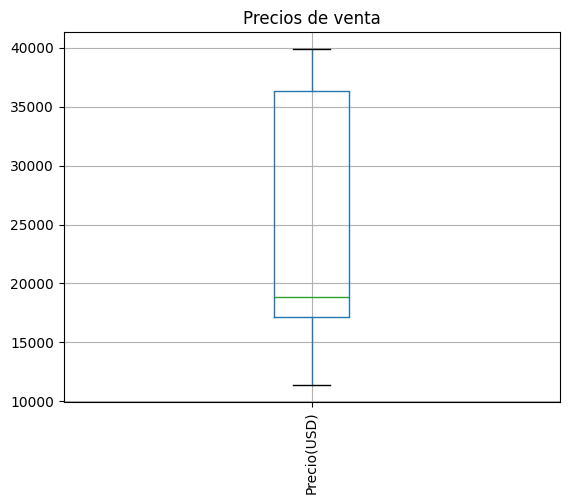

In [ ]:
df.boxplot('precio_venta(USD)',rot=90)
plt.title("Precios de venta")
plt.xticks([1], ['Precio(USD)'])
plt.show()

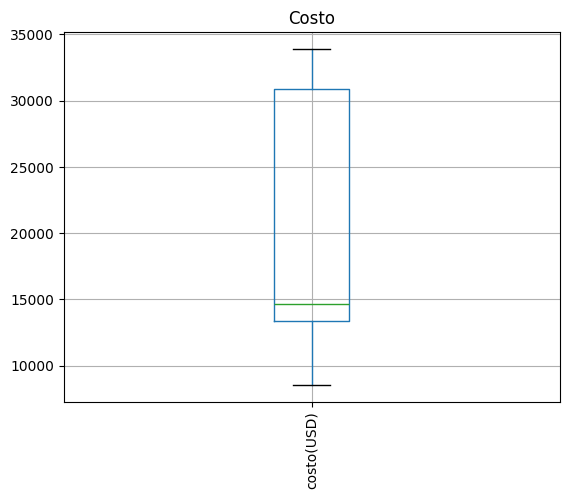

In [ ]:
df.boxplot('costo(USD)',rot=90)
plt.title("Costo")
plt.show()

En estos gráficos se puede ver que no hay presencia de valores outliers, extremos o atípicos que puedan afectar el análisis.

Ambos gráficos presentan una alta dispersión en la mitad superior de los datos, especialmente entre el cuartil 2 y 3. Esto indica que hay un grupo registros concentrados en valores de precio y costos bajos, y otro grupo de registros con precios y costos muy elevados que tienen menor frecuencia y mucha más dispersión. Por lo que ambas variables presentan una asimetría positiva (sesgada a la derecha).

En el caso del precio de venta, se observa una mediana cercana a los USD 18.800, con un rango que se extiende aproximadamente desde USD 11.400 hasta USD 40.000. La amplitud de la distribución sugiere que la concesionaria opera con un portafolio diversificado, ofreciendo vehículos en múltiples niveles de precio. Esto puede ser estratégicamente positivo porque permite atender distintos segmentos de clientes y diversificar el riesgo comercial.

El costo presenta una distribución proporcional al precio de venta, con una mediana cercana a USD 14.600 y un rango que oscila entre aproximadamente USD 8.500 y USD 34.000.

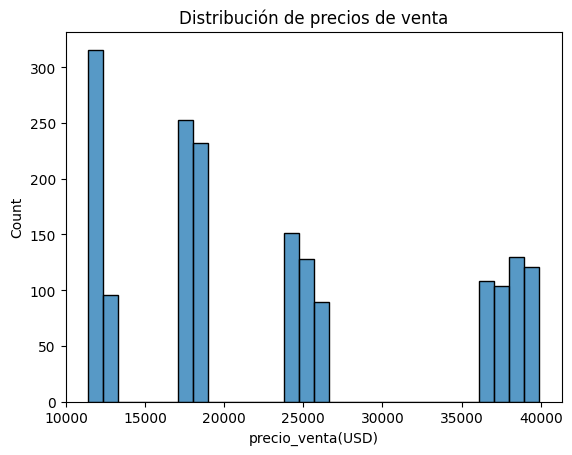

In [ ]:
# Distribución variables numéricas
sns.histplot(df["precio_venta(USD)"], bins=30)
plt.title("Distribución de precios de venta")
plt.show()

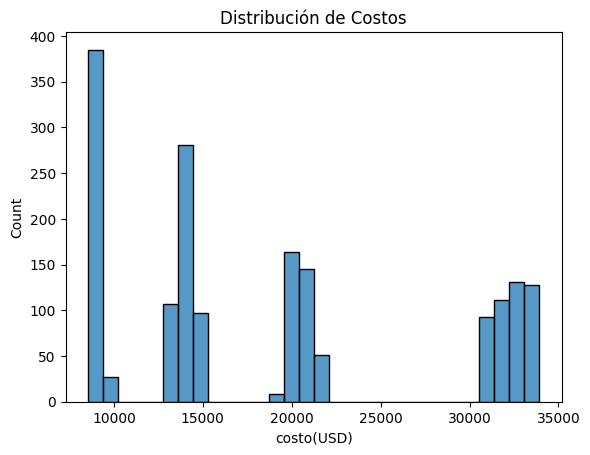

In [ ]:
sns.histplot(df['costo(USD)'], bins=30)
plt.title("Distribución de Costos")
plt.show()

Ambos histogramas (precio y costo) muestran una distribución multimodal, es decir, con varios picos claramente diferenciados. La presencia de estos picos indica que los precios no se distribuyen de manera continua, sino que están agrupados en segmentos definidos. Los gráficos confirman que la concesionaria trabaja con una estrategia de portafolio segmentado, ofreciendo vehículos en distintos niveles de precio para atender diferentes perfiles de clientes.

En el caso del precio de venta, se identifican cuatro grupos principales que corresponden a los distintos rangos de precio con los que trabaja la concesionaria: vehículos económicos (alrededor de USD 11.000–13.000), gama media (USD 17.000–19.000), gama media-alta (USD 24.000–26.000) y gama muy alta o premium (USD 36.000–40.000).

El comportamiento observado en la distribución de costos refleja una estructura similar, desplazada hacia valores menores.

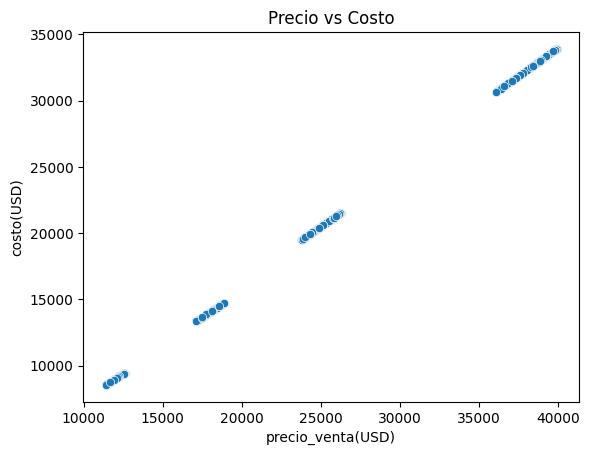

In [ ]:
# Relación precio y costo
sns.scatterplot(x=df['precio_venta(USD)'], y=df['costo(USD)'])
plt.title("Precio vs Costo")
plt.show()

Existe una correlación lineal positiva fuerte entre ambas variables. A medida que aumenta el precio de venta, el costo aumenta en la misma proporción. Esto indica que existe una regla de negocio fija o un margen de ganancia constante aplicado a los productos.

Se pueden apreciar también los 4 grupos que corresponden a los distintos rangos de precios de los vehículos de la concesionaria.

In [ ]:
# Calculamos la pendiente
pendiente, interseccion = np.polyfit(df['precio_venta(USD)'], df['costo(USD)'], 1)

print(f"La pendiente es: {pendiente:.2f}")

La pendiente es: 0.90


Por cada 1 USD que sube el precio de venta, el costo sube 0.90 USD. Esto implica que quedan 0.10 USD de margen bruto adicional por cada dólar de aumento en el precio.

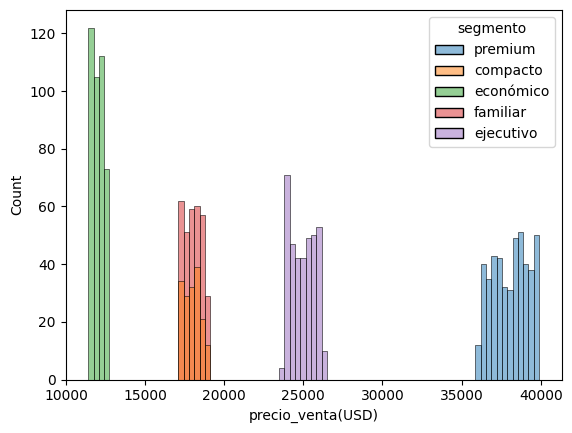

In [ ]:
sns.histplot(data = df, x = "precio_venta(USD)", bins=85, hue = "segmento")
plt.show()

Este gráfico muestra que cada segmento tiene un rango de precio bastante definido, lo que evidencia una estrategia de segmentación bien estructurada dentro del portafolio de productos. El segmento compacto y familiar comparten un mismo rango, lo que indica que la diferenciación entre ambos segmentos se basa en otros atributos que no tienen que ver con el precio de venta. Los vehículos del segmento “económico” se concentran en valores cercanos a los USD 11.000/13.000, mientras que los segmentos “compacto” y “familiar” se ubican en rangos intermedios cercanos a los USD 17.000/19.000. Por su parte, los vehículos “ejecutivos” presentan precios cercanos a los USD 24.000/26.000, y el segmento “premium” alcanza valores superiores a los USD 36.000. Esta estructura permite atender distintos niveles de poder adquisitivo, proporcionar productos para diferentes necesidades y mantener diferenciación entre categorías.

In [ ]:
df.groupby("segmento")["precio_venta(USD)"].agg(["max", "min", "mean"]).round(2)

,max,min,mean
segmento,,,
compacto,18900.0,17100.0,17971.44
económico,12600.0,11400.0,11997.93
ejecutivo,26250.0,23775.0,24961.01
familiar,18900.0,17100.0,18018.45
premium,39900.0,36100.0,38064.02


Con esta tabla se puede ver en números precisos el rango de precio de cada segmento y su promedio (segmentación clara del mercado). La diferencia entre el segmento “económico” y el “Premium” es de aproximadamente USD 26.000, lo que evidencia una fuerte diferenciación entre los extremos del portafolio de productos.

In [ ]:
df.groupby("segmento")["costo(USD)"].agg(["max", "min", "mean"]).round(2)

,max,min,mean
segmento,,,
compacto,14742.0,13338.0,14017.72
económico,9450.0,8550.0,8998.45
ejecutivo,21525.0,19495.5,20468.02
familiar,14742.0,13338.0,14054.39
premium,33915.0,30685.0,32354.41


Se observa una estructura similar a la anterior, donde el costo mantiene una proporción consistente respecto al precio de venta.

In [ ]:
df.groupby("canal_venta")["precio_venta(USD)"].agg(["mean"])

,mean
canal_venta,
corporativo,23799.231638
online,23297.809524
showroom,23452.723549


Se ve que no hay grandes diferencias de precios entre canales, no existe una concentración fuerte de vehículos más caros o más baratos en un canal específico. Este resultado indica que la empresa no utiliza los canales de venta para segmentar el tipo de vehículo ofrecido, sino que mantiene una estrategia multicanal donde los distintos segmentos de producto están disponibles a través de todos los canales de comercialización. Este enfoque tiene algunas ventajas como mayor flexibilidad comercial, mayor alcance de clientes y menor dependencia de un único canal de ventas.

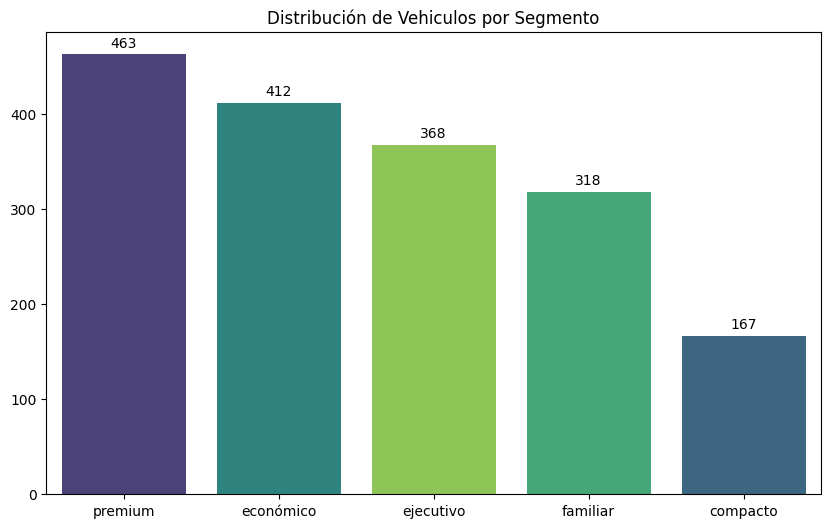

In [ ]:
orden = df["segmento"].value_counts().index

plt.figure(figsize=(10, 6))


ax = sns.countplot(
    data=df,
    x="segmento",
    order=orden,
    hue="segmento",
    palette='viridis',
    legend=False
)
ax.set_ylabel(None)
ax.set_xlabel(None)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Distribución de Vehiculos por Segmento")
plt.show()

Se puede observar que el segmento más vendido es el “Premium” seguido por el “económico”. Esto indica una estructura del portafolio con mayor presencia en los extremos del rango de precios. Por lo tanto, la empresa con su estrategia de mercado busca captar clientes de alto poder adquisitivo con productos de mayor valor y a su vez mantener volumen de ventas en segmentos de menor precio. El segmento “compacto” aparece como el menos representado, lo que podría indicar una menor diversidad de configuraciones dentro de ese tipo de vehículo, pudiendo afirmar que se trata de un producto más de nicho.

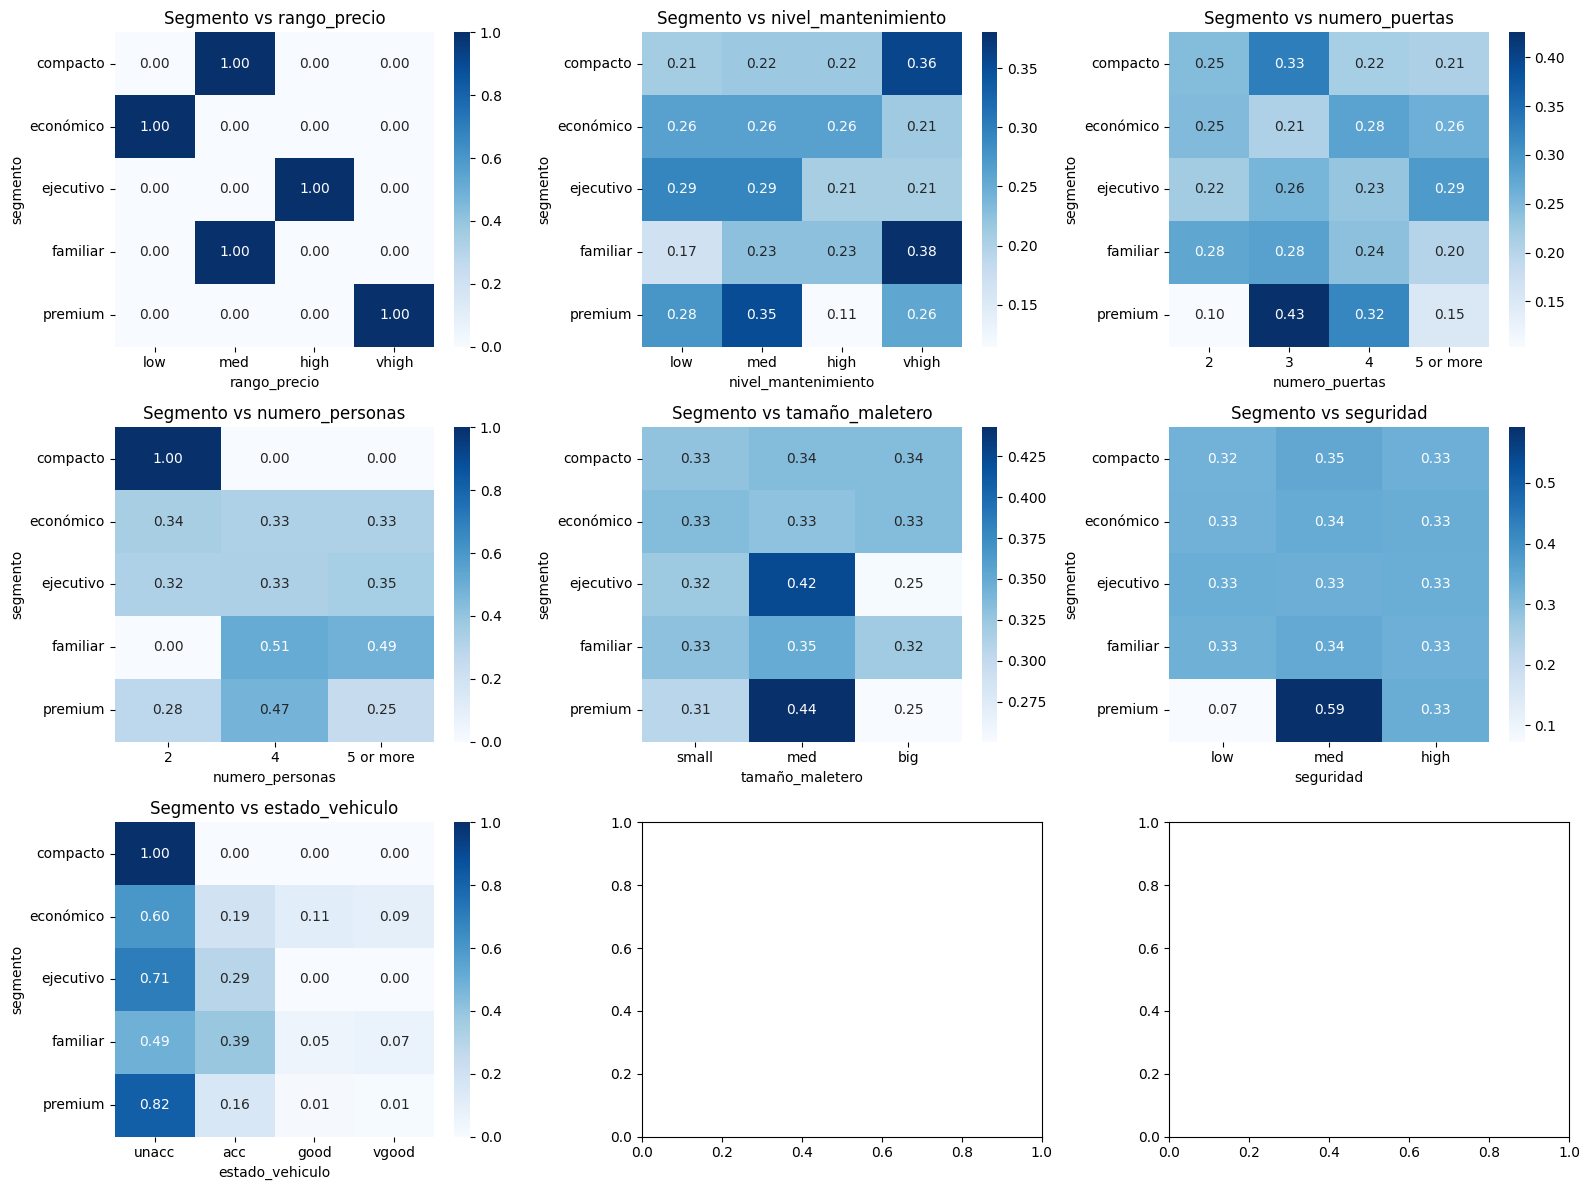

In [ ]:
variables = ['rango_precio', 'nivel_mantenimiento', 'numero_puertas','numero_personas',"tamaño_maletero","seguridad","estado_vehiculo"]

fig, axes = plt.subplots(3, 3, figsize=(16,12))

axes = axes.flatten()

for i, var in enumerate(variables):

    tabla = pd.crosstab(df["segmento"], df[var], normalize="index")

    sns.heatmap(tabla,
                annot=True,
                fmt=".2f",
                cmap="Blues",
                ax=axes[i])

    axes[i].set_title(f"Segmento vs {var}")

plt.tight_layout()
plt.show()

Con respecto al segmento versus el **rango de precio**, se puede ver una relación perfecta, es decir que, como ya se ha mencionado anteriormente, el precio es determinante del segmento del vehículo. Esto confirma que el mercado está claramente segmentado por nivel de precio.

El otro determinante del segmento del vehículo que se puede observar para diferenciar entre los segmentos “familiar” y “compacto”, ya que ambos comparten el mismo rango de precios, es el **número de personas** que caben en el vehículo. En el caso del segmento “familiar” el auto debe tener capacidad para 4 o más personas y en el caso del segmento “compacto”, son autos con capacidad para 2 personas. Es decir que este último segmento apunta a personas solteras o parejas sin hijos.

En relación a las demás variables, no se pueden observar relaciones claras con los segmentos de vehículos ya que sus distribuciones son relativamente homogéneas. Se puede destacar que los vehículos “Premium” en general presentan mejores prestaciones de seguridad que el resto. Otro aspecto a tener en cuenta, es que la mayoría de los vehículos presentan un estado de “no aceptable”. Habría que analizar a qué puede deberse esto.

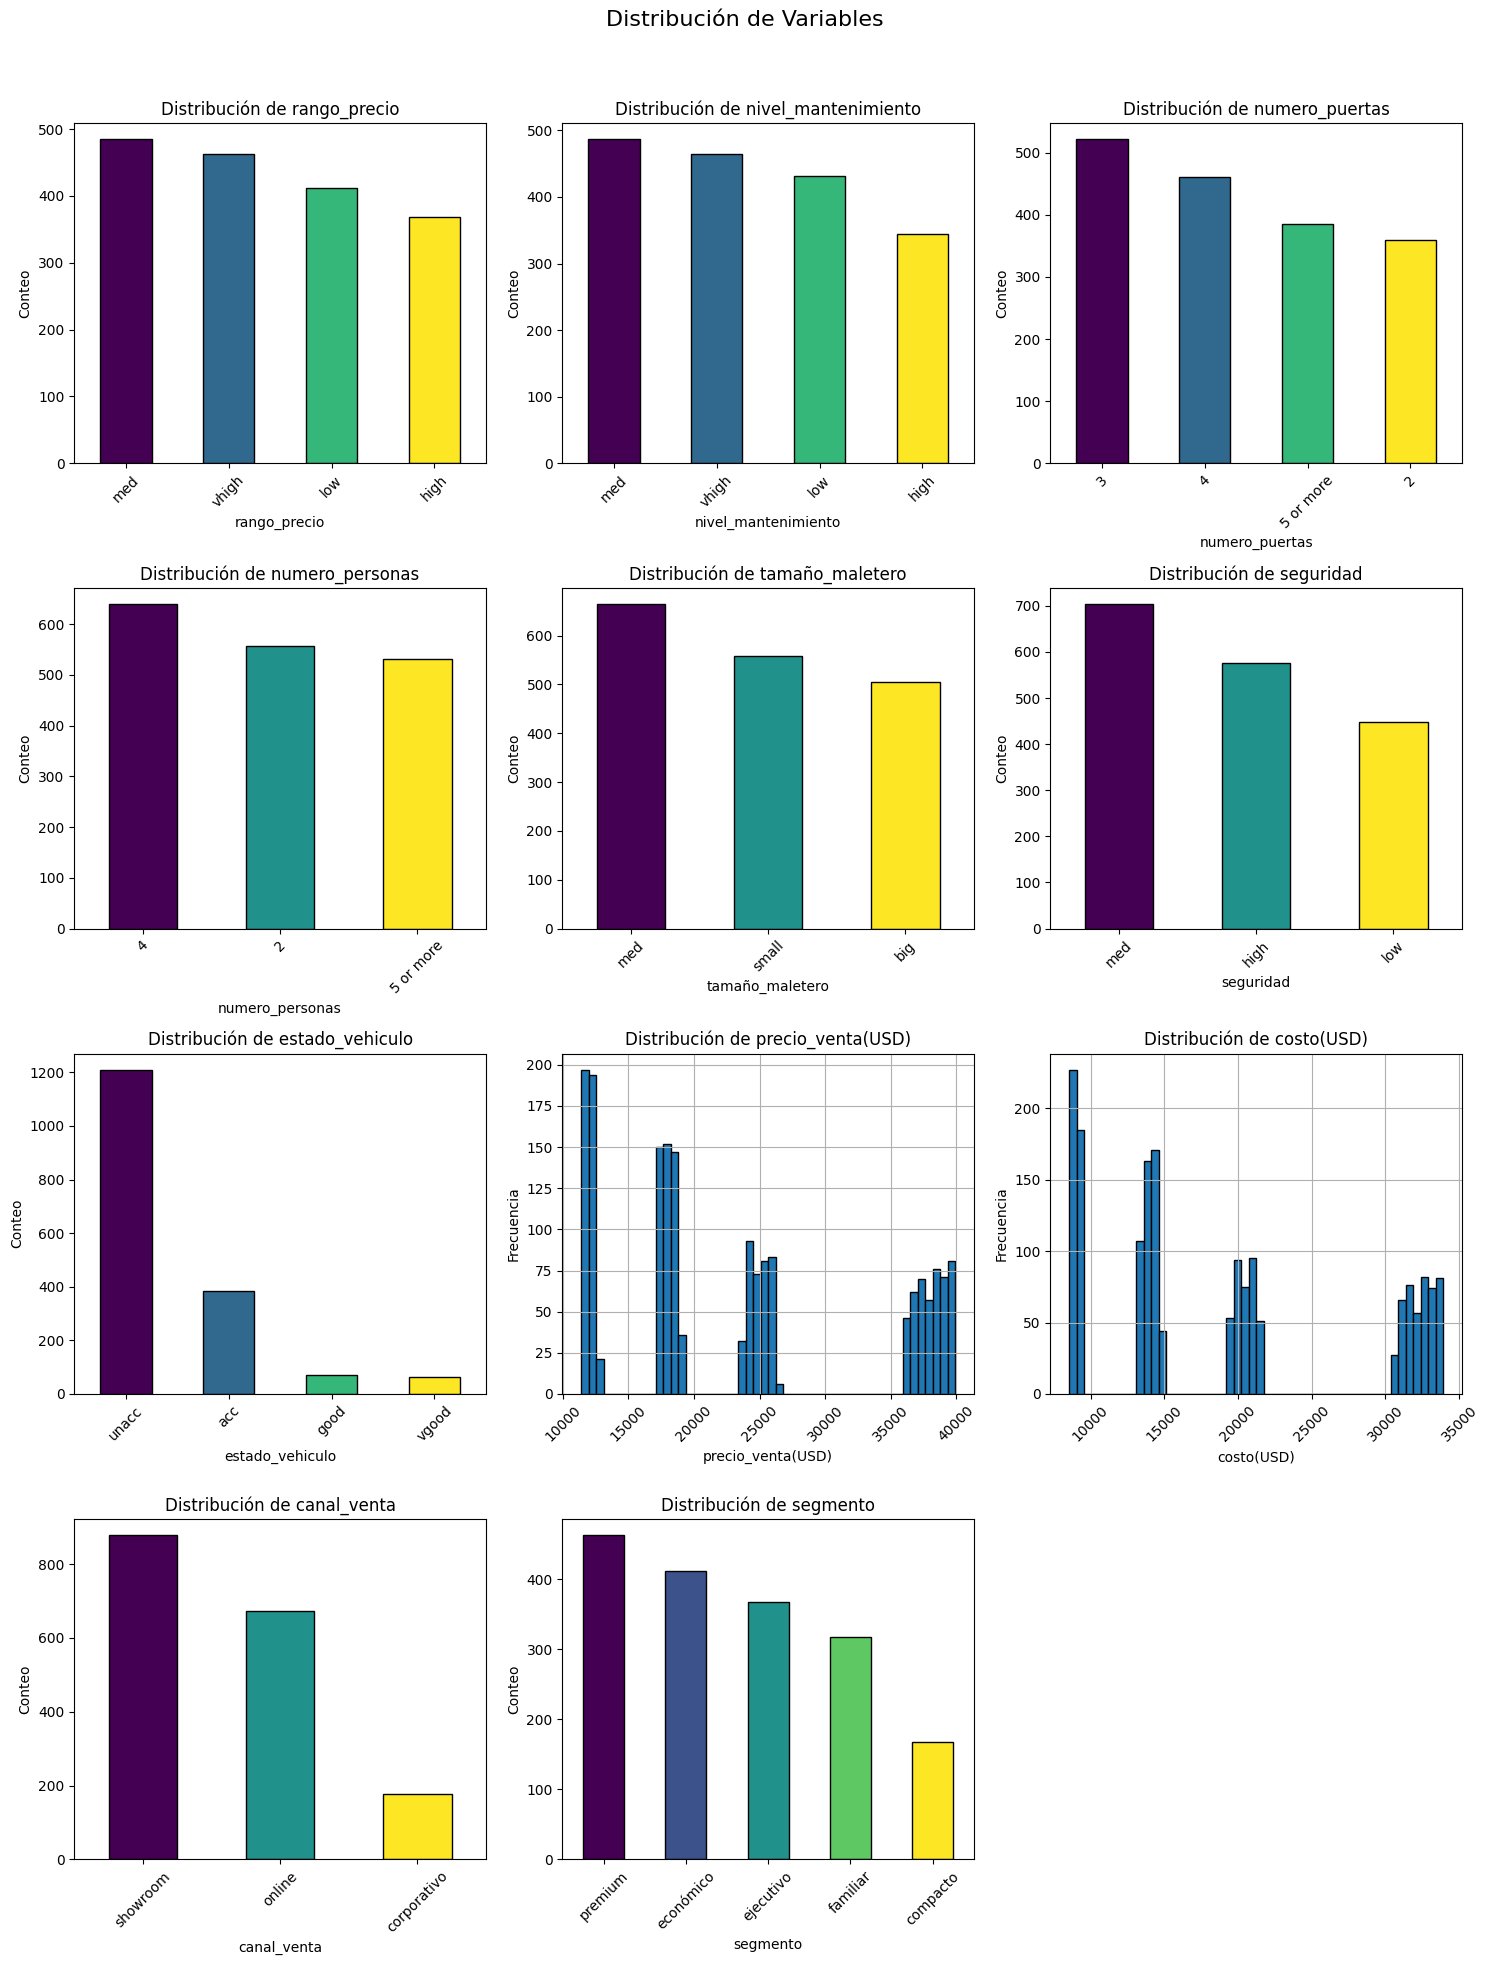

In [ ]:
# Resumen gráficos de distribución para todas las variables
columnas = df.columns.drop(["id", "fecha_operacion"])

n = len(columnas)
nrows = int(np.ceil(n / 3))
ncols = min(n, 3)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
fig.suptitle('Distribución de Variables', fontsize=16)

axes = np.array(axes).flatten()

for i, col in enumerate(columnas):
    ax = axes[i]

    if pd.api.types.is_numeric_dtype(df[col]):

        df[col].hist(ax=ax, bins=50, edgecolor='black')
        ax.set_xlabel(col)
        ax.set_ylabel('Frecuencia')

    else:
        conteo = df[col].value_counts()


        colores = plt.cm.viridis(np.linspace(0, 1, len(conteo)))

        conteo.plot(
            kind='bar',
            ax=ax,
            color=colores,
            edgecolor='black'
        )

        ax.set_xlabel(col)
        ax.set_ylabel('Conteo')

    ax.set_title(f'Distribución de {col}')
    ax.tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Conexión a BBDD (SQL)

Una vez finalizadas las tareas de limpieza, transformación y análisis exploratorio, se realizó la conexión entre Python y MySQL para transferir el conjunto de datos procesado.
Esta etapa permitió integrar el análisis realizado en Python con la fase posterior de modelado y consulta de datos en SQL.

In [ ]:
pip install mysql-connector-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 76.7 MB/s eta 0:00:00


In [ ]:
pip install pymysql

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.8 MB/s eta 0:00:00


In [ ]:
pip install sqlalchemy

In [ ]:
!pip install python-dotenv

In [ ]:
from dotenv import load_dotenv
import os

load_dotenv()

host = os.getenv("DB_HOST")
user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")
database = os.getenv("DB_NAME")
port = os.getenv("DB_PORT")

In [ ]:
from sqlalchemy import create_engine

engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"
)

ValueError: invalid literal for int() with base 10: 'None'

In [ ]:
df.to_sql(
    name="ventas",
    con=engine,
    if_exists="replace",
    index=False
)